# Pandas Practice Workbook — Netflix Dataset (125 Questions)
**Prepared by Ananda Rimal** · Dataset: `netflix_titles.csv`

**Columns:** `show_id, type, title, director, cast, country, date_added, release_year, rating, duration, listed_in, description`

**Instructions**
- Write your answer in the code cell **below each question**
- Every answer must be pandas code — no manual counting
- Sections G (GroupBy) and H (Cleaning) may need columns you create along the way — read carefully

| Section | Topic | Questions |
|---------|-------|-----------|
| A | First Analysis of Data | 15 |
| B | Selection with `[]`, `.loc`, `.iloc` | 25 |
| C | Conditions (with `.loc`) | 20 |
| D | Sorting | 10 |
| E | Updating Data | 15 |
| F | GroupBy | 20 |
| G | Cleaning | 20 |
| **Total** | | **125** |

## Section A — First Analysis of Data (Q1–Q15)

#### Q1. Load the dataset into a DataFrame called `df` and display the first 5 rows.

In [1]:
import pandas as pd
import numpy as np

In [2]:
netflix_df = pd.read_csv('./netflix_titles.csv')

#### Q2. Display the **last 7 rows** of the DataFrame.

In [3]:
netflix_df.head(7)

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...
5,s6,TV Show,Midnight Mass,Mike Flanagan,"Kate Siegel, Zach Gilford, Hamish Linklater, H...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",The arrival of a charismatic young priest brin...
6,s7,Movie,My Little Pony: A New Generation,"Robert Cullen, José Luis Ucha","Vanessa Hudgens, Kimiko Glenn, James Marsden, ...",NaN,"September 24, 2021",2021,PG,91 min,Children & Family Movies,Equestria's divided. But a bright-eyed hero be...


#### Q3. How many rows and columns does the dataset have?

In [4]:
no_of_columns = netflix_df.shape[1]
print("Number of columns in the dataset:", no_of_columns)

Number of columns in the dataset: 12


#### Q4. Display the names of all columns.

In [5]:
print(netflix_df.columns)

Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'description'],
      dtype='object')


#### Q5. Use `info()` — which columns have missing values, and what is the data type of each column?

In [6]:
netflix_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


#### Q6. Use `describe()` on the numeric columns. What is the minimum and maximum `release_year`?

In [7]:
netflix_df["release_year"].describe()

count    8807.000000
mean     2014.180198
std         8.819312
min      1925.000000
25%      2013.000000
50%      2017.000000
75%      2019.000000
max      2021.000000
Name: release_year, dtype: float64

#### Q7. Use `describe(include="object")` on the text columns. Which value appears most often in the `type` column?

In [8]:
netflix_df["director"].describe(include='object')

count              6173
unique             4528
top       Rajiv Chilaka
freq                 19
Name: director, dtype: object

#### Q8. Count the missing values in **every** column with one command.

In [9]:
netflix_df.isnull().sum()

show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64

#### Q9. Which single column has the **most** missing values?

In [10]:
highest_missing_column = netflix_df.isnull().sum().idxmax()
print("The highest number of missing values in a column is:", highest_missing_column)

The highest number of missing values in a column is: director


#### Q10. How many **unique** values are in the `rating` column? Display them.

In [11]:
netflix_df["rating"].unique()

array(['PG-13', 'TV-MA', 'PG', 'TV-14', 'TV-PG', 'TV-Y', 'TV-Y7', 'R',
       'TV-G', 'G', 'NC-17', '74 min', '84 min', '66 min', 'NR', nan,
       'TV-Y7-FV', 'UR'], dtype=object)

#### Q11. Show 5 **random** rows using `sample()`.

In [12]:
netflix_df.sample(5)

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
7058,s7059,Movie,Immoral Tales,Walerian Borowczyk,"Lise Danvers, Fabrice Luchini, Charlotte Alexa...",France,"June 6, 2019",1974,UR,103 min,"Dramas, International Movies, Romantic Movies",This anthology illustrates the timeless nature...
44,s45,Movie,Jaws: The Revenge,Joseph Sargent,"Lorraine Gary, Lance Guest, Mario Van Peebles,...",United States,"September 16, 2021",1987,PG-13,91 min,"Action & Adventure, Horror Movies, Thrillers","After another deadly shark attack, Ellen Brody..."
3054,s3055,Movie,Breaking the Bank,Vadim Jean,"Kelsey Grammer, Tamsin Greig, John Michael Hig...",United Kingdom,"January 1, 2020",2014,TV-PG,105 min,"Comedies, International Movies",Bank chairman Charles Bunbury – who knows next...
6320,s6321,Movie,Bittoo Boss,Supavitra Babul,"Pulkit Samrat, Ashok Pathak, Tanvir Singh, Ami...",India,"July 5, 2020",2012,TV-14,117 min,"Comedies, Dramas, International Movies",When a small-town wedding videographer falls i...
7082,s7083,TV Show,Inside the Mossad,NaN,NaN,Israel,"January 29, 2019",2017,TV-14,1 Season,"Docuseries, International TV Shows","In this documentary, dozens of former agents f..."


#### Q12. What is the memory usage of the DataFrame? (hint: `info()` or `memory_usage()`)

In [13]:
memory_usage = netflix_df.memory_usage().sum()
print("Total memory usage of the DataFrame:", memory_usage)

Total memory usage of the DataFrame: 845604


#### Q13. Display the data type of only the `release_year` column.

In [14]:
data_type = netflix_df["release_year"].dtype
print("Data type of the 'release_year' column:", data_type)

Data type of the 'release_year' column: int64


#### Q14. Count how many titles are of each `type` using `value_counts()`.

In [15]:
netflix_df["type"].value_counts()

type
Movie      6131
TV Show    2676
Name: count, dtype: int64

#### Q15. Check: does the dataset contain any **fully duplicated** rows?

In [16]:
duplicated_rows = netflix_df.duplicated().any()
print("Are there any duplicated rows?", duplicated_rows)

Are there any duplicated rows? False


## Section B — Selection with `[]`, `.loc`, `.iloc` (Q16–Q40)
*(Q16–Q30: default 0,1,2,... index · Q31–Q40: after `set_index("show_id")`)*

#### Q16. Select the `title` column as a **Series**.

In [17]:
netflix_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


In [18]:
type(netflix_df['title'])

pandas.core.series.Series

#### Q17. Select the `title` column as a **DataFrame** (hint: double brackets).

In [19]:
type(netflix_df[["title"]])

pandas.core.frame.DataFrame

#### Q18. Select the columns `title`, `type`, and `country` together.

In [20]:
netflix_df[['title','type','country']].head(5)

,title,type,country
0,Dick Johnson Is Dead,Movie,United States
1,Blood & Water,TV Show,South Africa
2,Ganglands,TV Show,NaN
3,Jailbirds New Orleans,TV Show,NaN
4,Kota Factory,TV Show,India


#### Q19. Select the first 10 rows using `.iloc`.

In [21]:
netflix_df.iloc[:10]

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...
5,s6,TV Show,Midnight Mass,Mike Flanagan,"Kate Siegel, Zach Gilford, Hamish Linklater, H...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",The arrival of a charismatic young priest brin...
6,s7,Movie,My Little Pony: A New Generation,"Robert Cullen, José Luis Ucha","Vanessa Hudgens, Kimiko Glenn, James Marsden, ...",NaN,"September 24, 2021",2021,PG,91 min,Children & Family Movies,Equestria's divided. But a bright-eyed hero be...
7,s8,Movie,Sankofa,Haile Gerima,"Kofi Ghanaba, Oyafunmike Ogunlano, Alexandra D...","United States, Ghana, Burkina Faso, United Kin...","September 24, 2021",1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies","On a photo shoot in Ghana, an American model s..."
8,s9,TV Show,The Great British Baking Show,Andy Devonshire,"Mel Giedroyc, Sue Perkins, Mary Berry, Paul Ho...",United Kingdom,"September 24, 2021",2021,TV-14,9 Seasons,"British TV Shows, Reality TV",A talented batch of amateur bakers face off in...
9,s10,Movie,The Starling,Theodore Melfi,"Melissa McCarthy, Chris O'Dowd, Kevin Kline, T...",United States,"September 24, 2021",2021,PG-13,104 min,"Comedies, Dramas",A woman adjusting to life after a loss contend...


#### Q20. Select rows with labels 10 to 20 using `.loc`. How many rows do you get and why?

- we get 11 rows becaues loc includes both starting and ending values i.e.<br> starting value :10 <br> ending value : 20

In [22]:
rows = netflix_df.loc[10:20]
print("rows:", rows.shape[0])
rows

rows: 11


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
10,s11,TV Show,"Vendetta: Truth, Lies and The Mafia",NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, Docuseries, International TV S...","Sicily boasts a bold ""Anti-Mafia"" coalition. B..."
11,s12,TV Show,Bangkok Breaking,Kongkiat Komesiri,"Sukollawat Kanarot, Sushar Manaying, Pavarit M...",NaN,"September 23, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...","Struggling to earn a living in Bangkok, a man ..."
12,s13,Movie,Je Suis Karl,Christian Schwochow,"Luna Wedler, Jannis Niewöhner, Milan Peschel, ...","Germany, Czech Republic","September 23, 2021",2021,TV-MA,127 min,"Dramas, International Movies",After most of her family is murdered in a terr...
13,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,"Klara Castanho, Lucca Picon, Júlia Gomes, Marc...",NaN,"September 22, 2021",2021,TV-PG,91 min,"Children & Family Movies, Comedies",When the clever but socially-awkward Tetê join...
14,s15,TV Show,Crime Stories: India Detectives,NaN,NaN,NaN,"September 22, 2021",2021,TV-MA,1 Season,"British TV Shows, Crime TV Shows, Docuseries",Cameras following Bengaluru police on the job ...
15,s16,TV Show,Dear White People,NaN,"Logan Browning, Brandon P. Bell, DeRon Horton,...",United States,"September 22, 2021",2021,TV-MA,4 Seasons,"TV Comedies, TV Dramas",Students of color navigate the daily slights a...
16,s17,Movie,Europe's Most Dangerous Man: Otto Skorzeny in ...,"Pedro de Echave García, Pablo Azorín Williams",NaN,NaN,"September 22, 2021",2020,TV-MA,67 min,"Documentaries, International Movies",Declassified documents reveal the post-WWII li...
17,s18,TV Show,Falsa identidad,NaN,"Luis Ernesto Franco, Camila Sodi, Sergio Goyri...",Mexico,"September 22, 2021",2020,TV-MA,2 Seasons,"Crime TV Shows, Spanish-Language TV Shows, TV ...",Strangers Diego and Isabel flee their home in ...
18,s19,Movie,Intrusion,Adam Salky,"Freida Pinto, Logan Marshall-Green, Robert Joh...",NaN,"September 22, 2021",2021,TV-14,94 min,Thrillers,After a deadly home invasion at a couple’s new...
19,s20,TV Show,Jaguar,NaN,"Blanca Suárez, Iván Marcos, Óscar Casas, Adriá...",NaN,"September 22, 2021",2021,TV-MA,1 Season,"International TV Shows, Spanish-Language TV Sh...","In the 1960s, a Holocaust survivor joins a gro..."


#### Q21. Using `.iloc`, select rows at positions 5 to 14 (10 rows). Compare with Q20 — why is the row count logic different?

- we get 10 rows because iloc excluded ending row position

In [23]:
rows = netflix_df.iloc[5:15]
print("rows:", rows.shape[0])
rows

rows: 10


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
5,s6,TV Show,Midnight Mass,Mike Flanagan,"Kate Siegel, Zach Gilford, Hamish Linklater, H...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",The arrival of a charismatic young priest brin...
6,s7,Movie,My Little Pony: A New Generation,"Robert Cullen, José Luis Ucha","Vanessa Hudgens, Kimiko Glenn, James Marsden, ...",NaN,"September 24, 2021",2021,PG,91 min,Children & Family Movies,Equestria's divided. But a bright-eyed hero be...
7,s8,Movie,Sankofa,Haile Gerima,"Kofi Ghanaba, Oyafunmike Ogunlano, Alexandra D...","United States, Ghana, Burkina Faso, United Kin...","September 24, 2021",1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies","On a photo shoot in Ghana, an American model s..."
8,s9,TV Show,The Great British Baking Show,Andy Devonshire,"Mel Giedroyc, Sue Perkins, Mary Berry, Paul Ho...",United Kingdom,"September 24, 2021",2021,TV-14,9 Seasons,"British TV Shows, Reality TV",A talented batch of amateur bakers face off in...
9,s10,Movie,The Starling,Theodore Melfi,"Melissa McCarthy, Chris O'Dowd, Kevin Kline, T...",United States,"September 24, 2021",2021,PG-13,104 min,"Comedies, Dramas",A woman adjusting to life after a loss contend...
10,s11,TV Show,"Vendetta: Truth, Lies and The Mafia",NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, Docuseries, International TV S...","Sicily boasts a bold ""Anti-Mafia"" coalition. B..."
11,s12,TV Show,Bangkok Breaking,Kongkiat Komesiri,"Sukollawat Kanarot, Sushar Manaying, Pavarit M...",NaN,"September 23, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...","Struggling to earn a living in Bangkok, a man ..."
12,s13,Movie,Je Suis Karl,Christian Schwochow,"Luna Wedler, Jannis Niewöhner, Milan Peschel, ...","Germany, Czech Republic","September 23, 2021",2021,TV-MA,127 min,"Dramas, International Movies",After most of her family is murdered in a terr...
13,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,"Klara Castanho, Lucca Picon, Júlia Gomes, Marc...",NaN,"September 22, 2021",2021,TV-PG,91 min,"Children & Family Movies, Comedies",When the clever but socially-awkward Tetê join...
14,s15,TV Show,Crime Stories: India Detectives,NaN,NaN,NaN,"September 22, 2021",2021,TV-MA,1 Season,"British TV Shows, Crime TV Shows, Docuseries",Cameras following Bengaluru police on the job ...


#### Q22. Using `.loc`, select rows 0 to 9 with only the columns `title` and `release_year`.

In [24]:
netflix_df[['title','release_year']].loc[:9]

,title,release_year
0,Dick Johnson Is Dead,2020
1,Blood & Water,2021
2,Ganglands,2021
3,Jailbirds New Orleans,2021
4,Kota Factory,2021
5,Midnight Mass,2021
6,My Little Pony: A New Generation,2021
7,Sankofa,1993
8,The Great British Baking Show,2021
9,The Starling,2021


#### Q23. Using `.iloc`, select the first 8 rows and the first 5 columns.

In [25]:
netflix_df.iloc[:8,:5]

,show_id,type,title,director,cast
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi..."
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K..."
5,s6,TV Show,Midnight Mass,Mike Flanagan,"Kate Siegel, Zach Gilford, Hamish Linklater, H..."
6,s7,Movie,My Little Pony: A New Generation,"Robert Cullen, José Luis Ucha","Vanessa Hudgens, Kimiko Glenn, James Marsden, ..."
7,s8,Movie,Sankofa,Haile Gerima,"Kofi Ghanaba, Oyafunmike Ogunlano, Alexandra D..."


#### Q24. Using `.iloc`, select the **last row** of the DataFrame.

In [26]:
netflix_df.iloc[[-1]]

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
8806,s8807,Movie,Zubaan,Mozez Singh,"Vicky Kaushal, Sarah-Jane Dias, Raaghav Chanan...",India,"March 2, 2019",2015,TV-14,111 min,"Dramas, International Movies, Music & Musicals",A scrappy but poor boy worms his way into a ty...


#### Q25. Using `.iloc`, select the last 5 rows and the last 2 columns (negative positions).

In [27]:
netflix_df.iloc[-5:,-2:]

,listed_in,description
8802,"Cult Movies, Dramas, Thrillers","A political cartoonist, a crime reporter and a..."
8803,"Kids' TV, Korean TV Shows, TV Comedies","While living alone in a spooky town, a young g..."
8804,"Comedies, Horror Movies",Looking to survive in a world taken over by zo...
8805,"Children & Family Movies, Comedies","Dragged from civilian life, a former superhero..."
8806,"Dramas, International Movies, Music & Musicals",A scrappy but poor boy worms his way into a ty...


#### Q26. Using `.loc`, get the value of `title` for the row with label 50.

In [28]:
netflix_df["title"].loc[5:10]

5                           Midnight Mass
6        My Little Pony: A New Generation
7                                 Sankofa
8           The Great British Baking Show
9                            The Starling
10    Vendetta: Truth, Lies and The Mafia
Name: title, dtype: object

#### Q27. Using `.iloc`, get the value in row position 100, column position 2. Which column is that?

In [29]:
netflix_df.iloc[100,2]

'Tobot Galaxy Detectives'

#### Q28. Using `.iloc`, select every 100th row (hint: slicing with a step `::100`).

In [30]:
netflix_df.iloc[::100]

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
100,s101,TV Show,Tobot Galaxy Detectives,NaN,"Austin Abell, Travis Turner, Cole Howard, Anna...",NaN,"September 7, 2021",2019,TV-Y7,2 Seasons,Kids' TV,An intergalactic device transforms toy cars in...
200,s201,Movie,Krishna Cottage,Santram Varma,"Sohail Khan, Isha Koppikar, Natassha, Rati Agn...",India,"August 27, 2021",2004,TV-14,124 min,"Action & Adventure, Horror Movies, Internation...",True love is put to the test when another woma...
300,s301,Movie,Vivo,"Kirk DeMicco, Brandon Jeffords","Lin-Manuel Miranda, Ynairaly Simo, Zoe Saldana...","Canada, United States","August 6, 2021",2021,PG,100 min,"Children & Family Movies, Music & Musicals",A music-loving kinkajou embarks on the journey...
400,s401,TV Show,Revelations: The Masters of the Universe: Reve...,NaN,"Kevin Smith, Tiffany Smith, Robert David, Sara...",NaN,"July 23, 2021",2021,TV-PG,1 Season,"Anime Series, Stand-Up Comedy & Talk Shows",Take a behind-the-scenes look at “Masters of t...
...,...,...,...,...,...,...,...,...,...,...,...,...
8400,s8401,Movie,The Long Goodbye: The Kara Tippetts Story,Jay Lyons,NaN,United States,"June 23, 2019",2019,TV-PG,87 min,"Documentaries, Faith & Spirituality","Faced with terminal breast cancer, a courageou..."
8500,s8501,Movie,The Search for Life in Space,Stephen Amezdroz,NaN,United States,"April 1, 2018",2016,TV-G,32 min,Documentaries,To determine whether we're alone in the univer...
8600,s8601,TV Show,Tobot,NaN,"Octavian Kaul, Valin Shinyei, Chelsea Miller, ...",Canada,"September 11, 2019",2018,TV-Y7,2 Seasons,"Kids' TV, Korean TV Shows",They’re robots that can transform into cars – ...
8700,s8701,TV Show,Wartime Portraits,NaN,NaN,Poland,"September 15, 2016",2014,TV-MA,1 Season,"Docuseries, International TV Shows","Part live-action and part animation, this visu..."


#### Q29. Using `.loc`, select rows 0 to 4 and **all** columns from `title` to `country` (label slicing on columns!).

In [31]:
netflix_df.loc[:4,'title':'country']

,title,director,cast,country
0,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States
1,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa
2,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN
3,Jailbirds New Orleans,NaN,NaN,NaN
4,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India


#### Q30. Select three specific rows by label — 3, 33, and 333 — in one `.loc` call.

In [32]:
netflix_df.iloc[[3,33,333]]

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
33,s34,TV Show,Squid Game,NaN,"Lee Jung-jae, Park Hae-soo, Wi Ha-jun, Oh Youn...",NaN,"September 17, 2021",2021,TV-MA,1 Season,"International TV Shows, TV Dramas, TV Thrillers",Hundreds of cash-strapped players accept a str...
333,s334,Movie,Ferris Bueller's Day Off,John Hughes,"Matthew Broderick, Alan Ruck, Mia Sara, Jeffre...",United States,"August 1, 2021",1986,PG-13,103 min,"Classic Movies, Comedies, Cult Movies","After faking an illness to skip school, popula..."


#### Q31. Set `show_id` as the index of `df` (keep it for the rest of Section B). Display the head.

In [33]:
df = pd.read_csv('./netflix_titles.csv')
df.set_index('show_id', inplace=True)
df.head(5)


,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
show_id,,,,,,,,,,,
s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


#### Q32. Using `.loc`, select the row with label `"s1"`.

In [34]:
df.loc[['s1']]

,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
show_id,,,,,,,,,,,
s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."


#### Q33. Using `.loc`, select rows `"s10"` to `"s15"`. Does label slicing still include the end?

In [35]:
df.loc['s10':'s15']

,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
show_id,,,,,,,,,,,
s10,Movie,The Starling,Theodore Melfi,"Melissa McCarthy, Chris O'Dowd, Kevin Kline, T...",United States,"September 24, 2021",2021,PG-13,104 min,"Comedies, Dramas",A woman adjusting to life after a loss contend...
s11,TV Show,"Vendetta: Truth, Lies and The Mafia",NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, Docuseries, International TV S...","Sicily boasts a bold ""Anti-Mafia"" coalition. B..."
s12,TV Show,Bangkok Breaking,Kongkiat Komesiri,"Sukollawat Kanarot, Sushar Manaying, Pavarit M...",NaN,"September 23, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...","Struggling to earn a living in Bangkok, a man ..."
s13,Movie,Je Suis Karl,Christian Schwochow,"Luna Wedler, Jannis Niewöhner, Milan Peschel, ...","Germany, Czech Republic","September 23, 2021",2021,TV-MA,127 min,"Dramas, International Movies",After most of her family is murdered in a terr...
s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,"Klara Castanho, Lucca Picon, Júlia Gomes, Marc...",NaN,"September 22, 2021",2021,TV-PG,91 min,"Children & Family Movies, Comedies",When the clever but socially-awkward Tetê join...
s15,TV Show,Crime Stories: India Detectives,NaN,NaN,NaN,"September 22, 2021",2021,TV-MA,1 Season,"British TV Shows, Crime TV Shows, Docuseries",Cameras following Bengaluru police on the job ...


#### Q34. Using `.iloc`, select the row at position 0. Is it the same row as label `"s1"`?

In [36]:
df.iloc[[0]]

,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
show_id,,,,,,,,,,,
s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."


#### Q35. Using `.loc`, get the `title` and `type` of the show with id `"s500"`.

In [37]:
df.loc[['s500'], ['title', 'type']]

,title,type
show_id,,
s500,Dogs,TV Show


#### Q36. Using `.iloc`, select the row at position 499. Is its label `"s500"`? Explain why or why not in a comment.

- Yes, its label is 's500' because Python uses zero-based positional indexing.
Position 499 represents the 500th row, whose show_id is 's500'

In [38]:
df.iloc[[499]]


,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
show_id,,,,,,,,,,,
s500,TV Show,Dogs,NaN,NaN,United States,"July 7, 2021",2021,TV-PG,2 Seasons,Docuseries,These six intimate stories explore the abiding...


#### Q37. Using `.loc`, select shows `"s1"`, `"s100"`, and `"s1000"` with columns `title` and `release_year`.

In [39]:
df.loc[['s1','s100','s1000'],['title','release_year']]

,title,release_year
show_id,,
s1,Dick Johnson Is Dead,2020
s100,On the Verge,2021
s1000,Stowaway,2021


#### Q38. What happens if you run `df.loc[0]` now? Try it, read the error, and explain in a comment.

- After setting show_id as the index, our DataFrame index contains labels such as: s1,s2,s3.... so 0 is no longer available in index

In [40]:
#  df.loc[0]

#### Q39. Using `.iloc`, select rows at positions [0, 99, 999] in one call.

In [41]:
df.iloc[[0,99,999]]

,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
show_id,,,,,,,,,,,
s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
s100,TV Show,On the Verge,NaN,"Julie Delpy, Elisabeth Shue, Sarah Jones, Alex...","France, United States","September 7, 2021",2021,TV-MA,1 Season,"TV Comedies, TV Dramas","Four women — a chef, a single mom, an heiress ..."
s1000,Movie,Stowaway,Joe Penna,"Anna Kendrick, Toni Collette, Daniel Dae Kim, ...","Germany, United States","April 22, 2021",2021,TV-MA,116 min,"Dramas, International Movies, Thrillers",A three-person crew on a mission to Mars faces...


#### Q40. Reset the index back to 0,1,2,... using `reset_index()`. Display the head.

In [42]:
df.reset_index(inplace=True)


## Section C — Conditions with `.loc` (Q41–Q60)
*Write every filter with `df.loc[condition]` or `df.loc[condition, columns]` style where possible.*

#### Q41. Select all rows where `type` is `"Movie"`.

In [43]:
df.loc[df['type'] == 'Movie']

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
6,s7,Movie,My Little Pony: A New Generation,"Robert Cullen, José Luis Ucha","Vanessa Hudgens, Kimiko Glenn, James Marsden, ...",NaN,"September 24, 2021",2021,PG,91 min,Children & Family Movies,Equestria's divided. But a bright-eyed hero be...
7,s8,Movie,Sankofa,Haile Gerima,"Kofi Ghanaba, Oyafunmike Ogunlano, Alexandra D...","United States, Ghana, Burkina Faso, United Kin...","September 24, 2021",1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies","On a photo shoot in Ghana, an American model s..."
9,s10,Movie,The Starling,Theodore Melfi,"Melissa McCarthy, Chris O'Dowd, Kevin Kline, T...",United States,"September 24, 2021",2021,PG-13,104 min,"Comedies, Dramas",A woman adjusting to life after a loss contend...
12,s13,Movie,Je Suis Karl,Christian Schwochow,"Luna Wedler, Jannis Niewöhner, Milan Peschel, ...","Germany, Czech Republic","September 23, 2021",2021,TV-MA,127 min,"Dramas, International Movies",After most of her family is murdered in a terr...
...,...,...,...,...,...,...,...,...,...,...,...,...
8801,s8802,Movie,Zinzana,Majid Al Ansari,"Ali Suliman, Saleh Bakri, Yasa, Ali Al-Jabri, ...","United Arab Emirates, Jordan","March 9, 2016",2015,TV-MA,96 min,"Dramas, International Movies, Thrillers",Recovering alcoholic Talal wakes up inside a s...
8802,s8803,Movie,Zodiac,David Fincher,"Mark Ruffalo, Jake Gyllenhaal, Robert Downey J...",United States,"November 20, 2019",2007,R,158 min,"Cult Movies, Dramas, Thrillers","A political cartoonist, a crime reporter and a..."
8804,s8805,Movie,Zombieland,Ruben Fleischer,"Jesse Eisenberg, Woody Harrelson, Emma Stone, ...",United States,"November 1, 2019",2009,R,88 min,"Comedies, Horror Movies",Looking to survive in a world taken over by zo...
8805,s8806,Movie,Zoom,Peter Hewitt,"Tim Allen, Courteney Cox, Chevy Chase, Kate Ma...",United States,"January 11, 2020",2006,PG,88 min,"Children & Family Movies, Comedies","Dragged from civilian life, a former superhero..."


#### Q42. Select all rows where `type` is `"TV Show"` — show only `title` and `country` using one `.loc` call.

In [44]:
df.loc[df['type'] == 'TV Show', ['title', 'country']]

,title,country
1,Blood & Water,South Africa
2,Ganglands,NaN
3,Jailbirds New Orleans,NaN
4,Kota Factory,India
5,Midnight Mass,NaN
...,...,...
8795,Yu-Gi-Oh! Arc-V,"Japan, Canada"
8796,Yunus Emre,Turkey
8797,Zak Storm,"United States, France, South Korea, Indonesia"
8800,Zindagi Gulzar Hai,Pakistan


#### Q43. Select all titles released in 2021.

In [45]:
df.loc[df['release_year'] == 2021, ['title','release_year']]

,title,release_year
1,Blood & Water,2021
2,Ganglands,2021
3,Jailbirds New Orleans,2021
4,Kota Factory,2021
5,Midnight Mass,2021
...,...,...
1468,What Happened to Mr. Cha?,2021
1551,Hilda,2021
1696,Polly Pocket,2021
2920,Love Is Blind,2021


#### Q44. Select all titles released **before** 2000.

In [46]:
df.loc[df["release_year"]<= 2000, ['title','release_year']]

,title,release_year
7,Sankofa,1993
22,Avvai Shanmughi,1996
24,Jeans,1998
26,Minsara Kanavu,1997
41,Jaws,1975
...,...,...
8745,Willy Wonka & the Chocolate Factory,1971
8748,Winter of Our Dreams,1981
8763,WWII: Report from the Aleutians,1943
8764,Wyatt Earp,1994


#### Q45. Select all titles released between 2015 and 2020 (inclusive) — two conditions with `&`.

In [47]:
df.loc[(df['release_year'] >= 2015) & (df['release_year'] <= 2020), ['title','release_year']]

,title,release_year
0,Dick Johnson Is Dead,2020
16,Europe's Most Dangerous Man: Otto Skorzeny in ...,2020
17,Falsa identidad,2020
21,Resurrection: Ertugrul,2018
32,Sex Education,2020
...,...,...
8796,Yunus Emre,2016
8797,Zak Storm,2016
8801,Zinzana,2015
8803,Zombie Dumb,2018


#### Q46. Select all Movies released after 2019 (two conditions).

In [48]:
df.loc[(df['type'] == 'Movie') & (df['release_year'] >= 2019), ['title','type','release_year']]

,title,type,release_year
0,Dick Johnson Is Dead,Movie,2020
6,My Little Pony: A New Generation,Movie,2021
9,The Starling,Movie,2021
12,Je Suis Karl,Movie,2021
13,Confessions of an Invisible Girl,Movie,2021
...,...,...,...
8516,The Spy Who Fell to Earth,Movie,2019
8631,Trixie Mattel: Moving Parts,Movie,2019
8718,Westside vs. the World,Movie,2019
8752,Wish Man,Movie,2019


#### Q47. Select all titles where `rating` is `"TV-MA"`.

In [49]:
df.loc[df['rating'] == 'TV-MA', ['title','rating']]

,title,rating
1,Blood & Water,TV-MA
2,Ganglands,TV-MA
3,Jailbirds New Orleans,TV-MA
4,Kota Factory,TV-MA
5,Midnight Mass,TV-MA
...,...,...
8762,Wrong Side Raju,TV-MA
8769,Y.M.I.: Yeh Mera India,TV-MA
8788,You Carry Me,TV-MA
8798,Zed Plus,TV-MA


#### Q48. Select all titles where `rating` is either `"PG"` or `"PG-13"` using `.isin()`.

In [50]:
df.loc[df['rating'].isin(["PG","PG-13"]), ['title','rating']]

,title,rating
0,Dick Johnson Is Dead,PG-13
6,My Little Pony: A New Generation,PG
9,The Starling,PG-13
27,Grown Ups,PG-13
28,Dark Skies,PG-13
...,...,...
8767,XXX: State of the Union,PG-13
8776,Yellowbird,PG
8782,Yoga Hosers,PG-13
8793,"Yours, Mine and Ours",PG


#### Q49. Select all titles where `rating` is **NOT** `"TV-MA"` (hint: `~` or `!=`).

In [51]:
df.loc[df['rating'] != 'TV-MA', ['title','rating']]

,title,rating
0,Dick Johnson Is Dead,PG-13
6,My Little Pony: A New Generation,PG
8,The Great British Baking Show,TV-14
9,The Starling,PG-13
13,Confessions of an Invisible Girl,TV-PG
...,...,...
8802,Zodiac,R
8803,Zombie Dumb,TV-Y7
8804,Zombieland,R
8805,Zoom,PG


#### Q50. Select all titles where `country` is exactly `"India"`.

In [52]:
df.loc[df['country'] == 'India', ['title','country']]

,title,country
4,Kota Factory,India
24,Jeans,India
39,Chhota Bheem,India
50,Dharmakshetra,India
66,Raja Rasoi Aur Anya Kahaniyan,India
...,...,...
8773,Yanda Kartavya Aahe,India
8775,Yeh Meri Family,India
8798,Zed Plus,India
8799,Zenda,India


#### Q51. Select all titles where `country` **contains** `"India"` (hint: `str.contains`, use `na=False`). Why is the row count different from the previous question?

- this will return every value of country where india is present anywhere for example index 29 has country United States, India, France but == returns only the exact individual india so the value count of rows is different

In [53]:
df.loc[df['country'].str.contains('India', na=False), ['title','country']]

,title,country
4,Kota Factory,India
24,Jeans,India
29,Paranoia,"United States, India, France"
39,Chhota Bheem,India
50,Dharmakshetra,India
...,...,...
8773,Yanda Kartavya Aahe,India
8775,Yeh Meri Family,India
8798,Zed Plus,India
8799,Zenda,India


#### Q52. Select all Movies from the United States — show only `title` and `release_year`.

In [54]:
df.loc[df['country'].str.contains('United States', na=False), ['title','release_year']]

,title,release_year
0,Dick Johnson Is Dead,2020
7,Sankofa,1993
9,The Starling,2021
15,Dear White People,2021
27,Grown Ups,2010
...,...,...
8793,"Yours, Mine and Ours",2005
8797,Zak Storm,2016
8802,Zodiac,2007
8804,Zombieland,2009


#### Q53. Select all titles where `director` is missing (hint: `isna()`).

In [55]:
df.loc[df['director'].isna(), ['title','director']]

,title,director
1,Blood & Water,NaN
3,Jailbirds New Orleans,NaN
4,Kota Factory,NaN
10,"Vendetta: Truth, Lies and The Mafia",NaN
14,Crime Stories: India Detectives,NaN
...,...,...
8795,Yu-Gi-Oh! Arc-V,NaN
8796,Yunus Emre,NaN
8797,Zak Storm,NaN
8800,Zindagi Gulzar Hai,NaN


#### Q54. Select all titles where `director` is **not** missing.

In [56]:
df.loc[df['director'].notnull(), ['title','director']]

,title,director
0,Dick Johnson Is Dead,Kirsten Johnson
2,Ganglands,Julien Leclercq
5,Midnight Mass,Mike Flanagan
6,My Little Pony: A New Generation,"Robert Cullen, José Luis Ucha"
7,Sankofa,Haile Gerima
...,...,...
8801,Zinzana,Majid Al Ansari
8802,Zodiac,David Fincher
8804,Zombieland,Ruben Fleischer
8805,Zoom,Peter Hewitt


#### Q55. Select all TV Shows released in 2020 **or** 2021.

In [57]:
df.loc[(df['type'] == 'TV Show') & ((df['release_year'] == 2020) | (df['release_year'] == 2021)), ['title','type','release_year']]

,title,type,release_year
1,Blood & Water,TV Show,2021
2,Ganglands,TV Show,2021
3,Jailbirds New Orleans,TV Show,2021
4,Kota Factory,TV Show,2021
5,Midnight Mass,TV Show,2021
...,...,...,...
3369,BoJack Horseman,TV Show,2020
3433,The Hook Up Plan,TV Show,2020
8125,Super Wings,TV Show,2020
8132,Surviving R. Kelly Part II: The Reckoning,TV Show,2020


#### Q56. Select all titles whose `title` starts with the letter `"A"` (hint: `str.startswith`, `na=False`).

In [58]:
df.loc[df['title'].str.startswith('A',na=False),['title']]

,title
22,Avvai Shanmughi
30,Ankahi Kahaniya
37,Angry Birds
71,A StoryBots Space Adventure
105,Angamaly Diaries
...,...
6198,Aussie Gold Hunters
6199,Automata
6200,Avengers: Infinity War
6201,Avicii: True Stories


#### Q57. Select all titles whose `title` contains the word `"Love"`.

In [59]:
df.loc[df['title'].str.contains('Love',na = False),['title']]

,title
25,Love on the Spectrum
158,Love Don't Cost a Thing
159,Love in a Puff
206,"LSD: Love, Sex Aur Dhokha"
227,Really Love
...,...
8567,The Year of Happiness and Love
8575,This Is My Love
8649,Two Lovers and a Bear
8721,What Is Love?


#### Q58. Using `.loc` with a condition, show the `title`, `rating`, and `release_year` of all Movies rated `"R"`.

In [60]:
df.loc[df['rating'] =='R',['title','rating','release_year']]

,title,rating,release_year
46,Safe House,R,2012
48,Training Day,R,2001
81,Kate,R,2021
122,In the Cut,R,2003
131,Blade Runner: The Final Cut,R,1982
...,...,...,...
8765,XX,R,2017
8768,Y Tu Mamá También,R,2001
8791,Young Adult,R,2011
8802,Zodiac,R,2007


#### Q59. Count how many Movies were released after 2015 (condition + `len()` or `.shape`).

In [61]:
len(df.loc[df['release_year'] >= 2015])


6216

#### Q60. Challenge: select all Movies that are from India **or** Nepal and released after 2010 — careful with brackets around the `|` condition!

In [62]:
df.loc[((df['country'] == 'India') | (df['country'] == 'Nepal'))&(df['release_year'] >= 2010),['title','country','release_year']]

,title,country,release_year
4,Kota Factory,India,2021
39,Chhota Bheem,India,2021
50,Dharmakshetra,India,2014
66,Raja Rasoi Aur Anya Kahaniyan,India,2014
69,Stories by Rabindranath Tagore,India,2015
...,...,...,...
8771,Yaara O Dildaara,India,2011
8772,Yamla Pagla Deewana 2,India,2013
8775,Yeh Meri Family,India,2018
8798,Zed Plus,India,2014


## Section D — Sorting (Q61–Q70)

#### Q61. Sort the DataFrame by `release_year` ascending. Show the head — what are the oldest titles?

In [63]:
df.sort_values(by='release_year', ascending=True).iloc[:10, [2, 7]]

,title,release_year
4250,Pioneers: First Women Filmmakers*,1925
7790,Prelude to War,1942
8205,The Battle of Midway,1942
8660,Undercover: How to Operate Behind Enemy Lines,1943
8739,Why We Fight: The Battle of Russia,1943
8763,WWII: Report from the Aleutians,1943
8640,Tunisian Victory,1944
8436,The Negro Soldier,1944
8419,The Memphis Belle: A Story of a\nFlying Fortress,1944
7930,San Pietro,1945


#### Q62. Sort by `release_year` **descending**. Show the 10 newest titles.

In [64]:
df.sort_values(by='release_year', ascending=False)[['title','release_year']].head(10)

,title,release_year
693,Ali & Ratu Ratu Queens,2021
781,Black Holes | The Edge of All We Know,2021
762,Sweet & Sour,2021
763,Sweet Tooth,2021
764,Trippin' with the Kandasamys,2021
765,Xtreme,2021
766,Alan Saldaña: Locked Up,2021
767,Creator's File: GOLD,2021
768,Dancing Queens,2021
770,Myriam Fares: The Journey,2021


#### Q63. Sort by `title` alphabetically.

In [65]:
df.sort_values(by = 'title',ascending=True)[['title']].head(1000)

,title
2036,#Alive
2304,#AnneFrank - Parallel Stories
2481,#FriendButMarried
2324,#FriendButMarried 2
5973,#Roxy
...,...
4616,Big Miracle
1590,Big Mouth
2419,Big Stone Gap
549,Big Timber


#### Q64. Sort by `release_year` descending AND `title` ascending at the same time (list of columns + list of ascending values).

In [66]:
df.sort_values(by = ['release_year', 'title'], ascending= True)[['title','release_year']].head(10)


,title,release_year
4250,Pioneers: First Women Filmmakers*,1925
7790,Prelude to War,1942
8205,The Battle of Midway,1942
8660,Undercover: How to Operate Behind Enemy Lines,1943
8763,WWII: Report from the Aleutians,1943
8739,Why We Fight: The Battle of Russia,1943
8419,The Memphis Belle: A Story of a\nFlying Fortress,1944
8436,The Negro Soldier,1944
8640,Tunisian Victory,1944
1331,Five Came Back: The Reference Films,1945


#### Q65. Sort by `rating`, and show only `title` and `rating` in the result.

In [67]:
df.sort_values(by = 'rating', ascending= True)[['title','rating']].head(10)

,title,rating
5813,Louis C.K.: Live at the Comedy Store,66 min
5541,Louis C.K. 2017,74 min
5794,Louis C.K.: Hilarious,84 min
8466,The Princess and the Frog,G
6151,An American Tail,G
1126,My Fair Lady,G
8455,The Pirate Fairy,G
2911,A Shaun the Sheep Movie: Farmageddon,G
3062,Jimmy Neutron: Boy Genius,G
1557,Canvas,G


#### Q66. Sort the **index** using `sort_index()` (useful after filtering).

In [68]:
df.sort_index()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...
...,...,...,...,...,...,...,...,...,...,...,...,...
8802,s8803,Movie,Zodiac,David Fincher,"Mark Ruffalo, Jake Gyllenhaal, Robert Downey J...",United States,"November 20, 2019",2007,R,158 min,"Cult Movies, Dramas, Thrillers","A political cartoonist, a crime reporter and a..."
8803,s8804,TV Show,Zombie Dumb,NaN,NaN,NaN,"July 1, 2019",2018,TV-Y7,2 Seasons,"Kids' TV, Korean TV Shows, TV Comedies","While living alone in a spooky town, a young g..."
8804,s8805,Movie,Zombieland,Ruben Fleischer,"Jesse Eisenberg, Woody Harrelson, Emma Stone, ...",United States,"November 1, 2019",2009,R,88 min,"Comedies, Horror Movies",Looking to survive in a world taken over by zo...
8805,s8806,Movie,Zoom,Peter Hewitt,"Tim Allen, Courteney Cox, Chevy Chase, Kate Ma...",United States,"January 11, 2020",2006,PG,88 min,"Children & Family Movies, Comedies","Dragged from civilian life, a former superhero..."


#### Q67. Show the 5 oldest Movies (filter first, then sort, then head).

In [69]:
df.loc[df['type'] == 'Movie'].sort_values(by = 'release_year',ascending=True)[['title','release_year','type']].head(5)


,title,release_year,type
7790,Prelude to War,1942,Movie
8205,The Battle of Midway,1942,Movie
8660,Undercover: How to Operate Behind Enemy Lines,1943,Movie
8763,WWII: Report from the Aleutians,1943,Movie
8739,Why We Fight: The Battle of Russia,1943,Movie


#### Q68. Show the 5 newest TV Shows.

In [70]:
df.loc[df['type']== 'TV Show'].sort_values(by = 'release_year',ascending=False)[['title','release_year','type']].head(5)

,title,release_year,type
1,Blood & Water,2021,TV Show
835,Eden,2021,TV Show
876,Alma Matters,2021,TV Show
874,Booba: Food Puzzle,2021,TV Show
862,Special,2021,TV Show


#### Q69. Sort by `country` and put the missing values **first** (hint: `na_position="first"`).

In [71]:
df.sort_values(by='country', ascending=True,na_position='first')[['title','country']].head(10)

,title,country
2,Ganglands,NaN
3,Jailbirds New Orleans,NaN
5,Midnight Mass,NaN
6,My Little Pony: A New Generation,NaN
10,"Vendetta: Truth, Lies and The Mafia",NaN
11,Bangkok Breaking,NaN
13,Confessions of an Invisible Girl,NaN
14,Crime Stories: India Detectives,NaN
16,Europe's Most Dangerous Man: Otto Skorzeny in ...,NaN
18,Intrusion,NaN


#### Q70. What does `ascending=[False, True]` mean when sorting by two columns? Demonstrate with `release_year` and `title` and explain in a comment.

- `[false , true]` means the release year will be in decending order but title will be in ascending order among titles having same release year

In [72]:
df.sort_values(by=['release_year', 'title'], ascending=[False, True])[['title','release_year']].head(10)

,title,release_year
1373,50M2,2021
1150,7 Yards: The Chris Norton Story,2021
850,99 Songs,2021
851,99 Songs (Tamil),2021
852,99 Songs (Telugu),2021
404,9to5: The Story of a Movement,2021
463,A Classic Horror Story,2021
683,A Family,2021
452,A Perfect Fit,2021
393,A Second Chance: Rivals!,2021


## Section E — Updating Data (Q71–Q85)

#### Q71. Rename the column `listed_in` to `genres` (keep this change).

In [73]:
df.rename(columns = {'listed_in':'genre'}, inplace = True)

#### Q72. Create a new column `age_years` = 2026 minus `release_year`.

In [74]:
df['age_years'] = 2026 - df['release_year']

#### Q73. Create a column `is_movie` that is `True` when `type` is `"Movie"`.

In [75]:
df['is_movie'] = df['type'] == 'Movie'

#### Q74. Create a column `is_recent` that is `True` when `release_year >= 2020`.

In [76]:
df['is_recent'] = df['release_year'] >= 2020

#### Q75. Using `.loc` with a condition, set `rating` to `"UNRATED"` for all rows where `rating` is missing.

In [77]:
df.loc[df['rating'].isna(),'rating'] = 'UNRATED'

#### Q76. Replace the value `"United States"` with `"USA"` in the `country` column (hint: `replace`).

In [78]:
df['country'] = df['country'].replace('United States', 'USA')

#### Q77. Convert all titles to UPPERCASE into a new column `title_upper` (hint: `str.upper`).

In [79]:
df['title_upper'] = df['title'].str.upper()

#### Q78. Create a column `title_length` = number of characters in each title (hint: `str.len`).

In [80]:
df['title_length'] = df['title'].str.len()


#### Q79. Using `.loc`, change the `title` of the row with index label 0 to `"My Favourite Show"`. Display that row to confirm.

In [81]:
df.loc[0,'title'] = "My Favorite Show"
df.loc[[0]]

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,genre,description,age_years,is_movie,is_recent,title_upper,title_length
0,s1,Movie,My Favorite Show,Kirsten Johnson,NaN,USA,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm...",6,True,True,DICK JOHNSON IS DEAD,20


#### Q80. Add a column `platform` where every row has the value `"Netflix"`.

In [82]:
df['platform'] = 'Netflix'

#### Q81. Delete the column `title_upper` using `drop`.

In [83]:
df.drop(columns = 'title_upper', inplace = True)

#### Q82. Change `release_year` to type `int32` using `astype`. Check with `dtypes`.

In [84]:
df['release_year'] = df['release_year'].astype('int64')

In [85]:
df['release_year'].dtype

dtype('int64')

#### Q83. Using `.loc` with a condition, create/overwrite a column `era` = `"old"` for titles before 2010 and `"new"` for 2010 onward (two `.loc` assignments, or `np.where`).

In [86]:
df['era'] = np.where(df['release_year'] < 2010, 'old', 'new')

In [87]:
df.head(2)

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,genre,description,age_years,is_movie,is_recent,title_length,platform,era
0,s1,Movie,My Favorite Show,Kirsten Johnson,NaN,USA,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm...",6,True,True,20,Netflix,new
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",5,False,True,13,Netflix,new


#### Q84. Increase `age_years` by 1 for **all** rows in one operation.

In [88]:
df['age_years'] = df['age_years'] + 1
df.head(1)

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,genre,description,age_years,is_movie,is_recent,title_length,platform,era
0,s1,Movie,My Favorite Show,Kirsten Johnson,NaN,USA,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm...",7,True,True,20,Netflix,new


#### Q85. Explain in a markdown comment: why is `df.loc[condition, "col"] = value` the SAFE way to update, instead of `df[condition]["col"] = value`? (SettingWithCopyWarning!)

- `df.loc[condition, "col"] = value` directly updates the specified column in the original DataFrame.
- `df[condition]["col"] = value` first creates a filtered DataFrame, which may be a copy rather than a view of the original DataFrame.<br>
Therefore, changes made through chained indexing may not affect the original DataFrame.

## Section F — GroupBy (Q86–Q105)

#### Q86. Group by `type` and count the number of titles in each group (`size()`).

In [89]:
df.groupby('type').size()

type
Movie      6131
TV Show    2676
dtype: int64

#### Q87. Group by `rating` and count titles. Which rating is most common?

In [90]:
df.groupby('rating').size()

rating
66 min         1
74 min         1
84 min         1
G             41
NC-17          3
NR            80
PG           287
PG-13        490
R            799
TV-14       2160
TV-G         220
TV-MA       3207
TV-PG        863
TV-Y         307
TV-Y7        334
TV-Y7-FV       6
UNRATED        4
UR             3
dtype: int64

#### Q88. Group by `release_year` and count titles. Which year had the most releases?

In [91]:
df.groupby('release_year').size()

release_year
1925       1
1942       2
1943       3
1944       3
1945       4
        ... 
2017    1032
2018    1147
2019    1030
2020     953
2021     592
Length: 74, dtype: int64

In [92]:
df.groupby('release_year').size().idxmax()

np.int64(2018)

#### Q89. Group by `type` and find the **minimum** and **maximum** `release_year` for each (hint: `agg(["min","max"])`).

In [93]:
df.groupby('type')['release_year'].agg(['min','max'])

,min,max
type,,
Movie,1942,2021
TV Show,1925,2021


#### Q90. Group by `type` and compute the **average** `age_years`.

In [94]:
df.groupby('type')['age_years'].mean()

type
Movie      13.878486
TV Show    10.394245
Name: age_years, dtype: float64

#### Q91. Group by `country` and count titles — show only the top 10 (sort + head).

In [95]:
df.groupby('country').size().sort_values(ascending=False).head(10)

country
USA               2818
India              972
United Kingdom     419
Japan              245
South Korea        199
Canada             181
Spain              145
France             124
Mexico             110
Egypt              106
dtype: int64

#### Q92. Group by `rating` and compute the average `title_length`.

In [96]:
df.groupby('rating')[['title_length']].mean()

,title_length
rating,
66 min,36.000000
74 min,15.000000
84 min,21.000000
G,20.560976
NC-17,17.666667
NR,16.075000
PG,18.285714
PG-13,16.014286
R,14.898623


#### Q93. Group by `era` (from Q83) and count Movies vs TV Shows (hint: group by TWO columns).

In [97]:
df.groupby(['type','era'])['type'].size()

type     era
Movie    new    4978
         old    1153
TV Show  new    2494
         old     182
Name: type, dtype: int64

#### Q94. Group by `type` and `rating` together and count. Display the result with `unstack()`.

In [98]:
df.groupby(['type','rating']).size().unstack()

rating,66 min,74 min,84 min,G,NC-17,NR,PG,PG-13,R,TV-14,TV-G,TV-MA,TV-PG,TV-Y,TV-Y7,TV-Y7-FV,UNRATED,UR
type,,,,,,,,,,,,,,,,,,
Movie,1.0,1.0,1.0,41.0,3.0,75.0,287.0,490.0,797.0,1427.0,126.0,2062.0,540.0,131.0,139.0,5.0,2.0,3.0
TV Show,NaN,NaN,NaN,NaN,NaN,5.0,NaN,NaN,2.0,733.0,94.0,1145.0,323.0,176.0,195.0,1.0,2.0,NaN


#### Q95. For Movies only: group by `release_year` and count — how many movies came out each year since 2015? (filter first, then group, then `.tail()`)

In [99]:
df.loc[(df['type'] == 'Movie')&(df['release_year']>=2015)].groupby('release_year').size().tail()

release_year
2017    767
2018    767
2019    633
2020    517
2021    277
dtype: int64

#### Q96. Group by `country` and compute the average `release_year` — which 5 countries have the 'newest' catalogs on average? (sort descending, head)

In [100]:
df.groupby(['country'])['release_year'].mean().sort_values(ascending= True).head(5)

country
India, Malaysia                                        1960.0
United States, Italy, United Kingdom, Liechtenstein    1965.0
United States, East Germany, West Germany              1971.0
United Kingdom, West Germany                           1972.0
Poland,                                                1975.0
Name: release_year, dtype: float64

#### Q97. Use `value_counts()` on `genres` — why does this NOT give clean genre counts? Explain in a comment (hint: multiple genres in one cell).

- This does not give clean genre counts because multiple genres are stored in a single cell (e.g., "Comedies, Dramas, International Movies"). value_counts() treats each unique combination as one category instead of counting each individual genre separately.

In [101]:
df['genre'].value_counts()

genre
Dramas, International Movies                          362
Documentaries                                         359
Stand-Up Comedy                                       334
Comedies, Dramas, International Movies                274
Dramas, Independent Movies, International Movies      252
                                                     ... 
Kids' TV, TV Action & Adventure, TV Dramas              1
TV Comedies, TV Dramas, TV Horror                       1
Children & Family Movies, Comedies, LGBTQ Movies        1
Kids' TV, Spanish-Language TV Shows, Teen TV Shows      1
Cult Movies, Dramas, Thrillers                          1
Name: count, Length: 514, dtype: int64

#### Q98. Group by `is_recent` and count — how many recent vs old titles?

In [102]:
df['is_recent'].value_counts()

is_recent
False    7262
True     1545
Name: count, dtype: int64

#### Q99. Group by `type` and use `.agg()` with a dictionary: count of `title` and mean of `age_years` in ONE command.

In [103]:
df.groupby('type').agg({'title':'count','age_years':'mean'})

,title,age_years
type,,
Movie,6131,13.878486
TV Show,2676,10.394245


#### Q100. Group by `rating` and show the **number of unique countries** per rating (hint: `nunique`).

In [104]:
df.groupby('rating')[['title']].nunique()

,title
rating,
66 min,1
74 min,1
84 min,1
G,41
NC-17,3
NR,80
PG,287
PG-13,490
R,799


#### Q101. Using `groupby` + `head(1)`, show the FIRST title (by current order) in each `type` group.

In [105]:
df.groupby('type').head(1)[['type','title']]

,type,title
0,Movie,My Favorite Show
1,TV Show,Blood & Water


#### Q102. Group by `release_year` and count, then plot it with `.plot()` (line chart). What trend do you see?

<Axes: title={'center': 'number of titles release per year'}, xlabel='release year', ylabel='number of titles'>

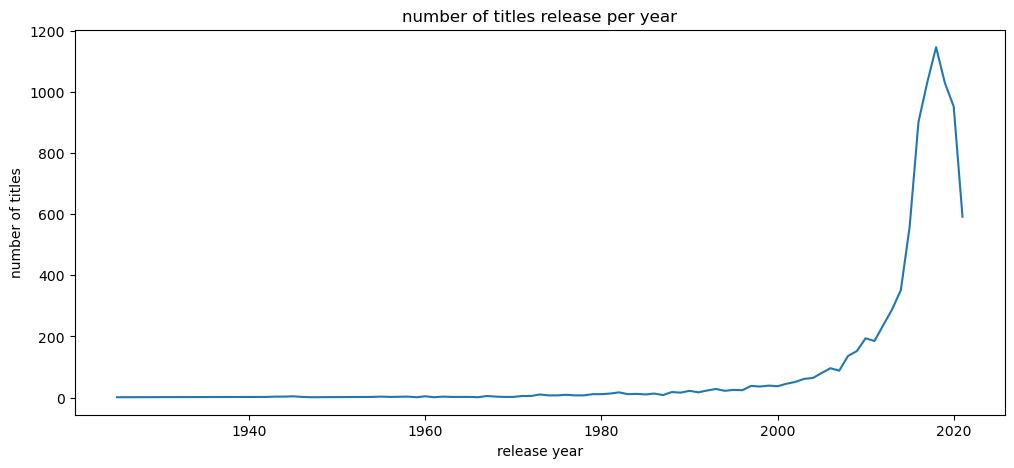

In [106]:
df.groupby('release_year')['title'].count().plot(
    kind='line',
    figsize=(12,5),
    title= 'number of titles release per year',
    xlabel='release year',
    ylabel='number of titles'
)

#### Q103. Group by `year_added`-style logic isn't possible yet — `date_added` is still text! Group by the **first 4 characters trick is wrong**. Explain in a comment why we need Section G (Cleaning) before we can group by the year a title was ADDED.

We cannot reliably group titles by the year they were added because
date_added is currently stored as text (object/string), not as a datetime.
<br>Extracting the first 4 characters is incorrect because date_added
follows a format like "September 9, 2019", where the year is at the end.<br>
We need Section G (Cleaning) to convert date_added into proper datetime
format using pd.to_datetime(), then extract the year using .dt.year

#### Q104. Group by `type` and compute the **median** `release_year`.

In [107]:
df.groupby(['type'])['release_year'].median()


type
Movie      2016.0
TV Show    2018.0
Name: release_year, dtype: float64

#### Q105. Challenge: for each `rating`, what percentage of titles are Movies? (hint: group by rating, compute the mean of `is_movie`, multiply by 100)

In [108]:
df.groupby('rating')['is_movie'].mean() * 100

rating
66 min      100.000000
74 min      100.000000
84 min      100.000000
G           100.000000
NC-17       100.000000
NR           93.750000
PG          100.000000
PG-13       100.000000
R            99.749687
TV-14        66.064815
TV-G         57.272727
TV-MA        64.296851
TV-PG        62.572422
TV-Y         42.671010
TV-Y7        41.616766
TV-Y7-FV     83.333333
UNRATED      50.000000
UR          100.000000
Name: is_movie, dtype: float64

## Section G — Cleaning (Q106–Q125)

#### Q106. Re-check missing values per column (things changed since Section A!).

In [109]:
df.isna().sum()

show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             0
duration           3
genre              0
description        0
age_years          0
is_movie           0
is_recent          0
title_length       0
platform           0
era                0
dtype: int64

#### Q107. Fill missing `director` values with `"Unknown"`.

In [110]:
df['director'] = df['director'].fillna('Unknown')

#### Q108. Fill missing `cast` values with `"Unknown"`.

In [111]:
df['cast'] = df['cast'].fillna('unknown')

#### Q109. Fill missing `country` values with the **most common** country (hint: `mode()[0]`).

In [112]:
df['country'] = df['country'].fillna(df['country'].mode()[0])

#### Q110. Count the rows where `date_added` is missing, then drop those rows.

In [113]:
df.dropna(subset=['date_added'],inplace=True)

#### Q111. `date_added` has extra spaces in some rows — strip them (hint: `str.strip`).

In [114]:
df['date_added'] = df['date_added'].str.strip()

#### Q112. Convert `date_added` to datetime with `pd.to_datetime`. Check the dtype after.

In [115]:
df['date_added'] = pd.to_datetime(df['date_added'])

#### Q113. NOW create `year_added` = `.dt.year` and `month_added` = `.dt.month_name()`.

In [116]:
df['year_added'] = df['date_added'].dt.year
df['month_added'] = df['date_added'].dt.month_name()

#### Q114. Group by `year_added` and count — which year did Netflix add the most content? (This is the question F103 could not answer!)

In [117]:
df.groupby(['year_added'])['year_added'].count().max()


2016

#### Q115. Group by `month_added` and count — which month is most popular for adding content?

In [118]:
df.groupby(['month_added'])['month_added'].count().idxmax()


'July'

#### Q116. Look at the `duration` column with `unique()` (first 20 values) — what TWO different formats do you see?

In [119]:
df['duration'].unique()[:20]

array(['90 min', '2 Seasons', '1 Season', '91 min', '125 min',
       '9 Seasons', '104 min', '127 min', '4 Seasons', '67 min', '94 min',
       '5 Seasons', '161 min', '61 min', '166 min', '147 min', '103 min',
       '97 min', '106 min', '111 min'], dtype=object)

#### Q117. Extract the number from `duration` into a new column `duration_int` (hint: `str.extract(r"(\\d+)")` then `astype(float)`).

In [120]:
df['duration_int'] = df['duration'].str.extract(r'(\d+)').astype(float)

In [121]:
df[['duration','duration_int']].head(10)

,duration,duration_int
0,90 min,90.0
1,2 Seasons,2.0
2,1 Season,1.0
3,1 Season,1.0
4,2 Seasons,2.0
5,1 Season,1.0
6,91 min,91.0
7,125 min,125.0
8,9 Seasons,9.0
9,104 min,104.0


#### Q118. For Movies only: what is the average, minimum, and maximum duration in minutes?

In [122]:
df.loc[df['type'] == 'Movie','duration_int'].agg(['mean','min','max'])


mean     99.577187
min       3.000000
max     312.000000
Name: duration_int, dtype: float64

#### Q119. For TV Shows only: how many have more than 5 seasons? Show their titles.

In [123]:
df.head(1)

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,...,description,age_years,is_movie,is_recent,title_length,platform,era,year_added,month_added,duration_int
0,s1,Movie,My Favorite Show,Kirsten Johnson,unknown,USA,2021-09-25,2020,PG-13,90 min,...,"As her father nears the end of his life, filmm...",7,True,True,20,Netflix,new,2021,September,90.0


In [124]:
df.loc[(df['type'] == 'TV Show') & (df['duration_int']> 5)][['title','duration_int']]

,title,duration_int
8,The Great British Baking Show,9.0
55,Nailed It,6.0
65,Numberblocks,6.0
67,Saved by the Bell,9.0
82,Lucifer,6.0
...,...,...
8189,The Andy Griffith Show,8.0
8378,The L Word,6.0
8442,The Office (U.S.),9.0
8557,The West Wing,7.0


#### Q120. Check duplicated **titles** (not full rows): are there any titles that appear more than once? Display them.

In [125]:
df['title'].duplicated().sum()

np.int64(0)

#### Q121. Are those duplicated titles real duplicates or different shows? Inspect a few with `.loc` and explain in a comment.

no,duplicates

#### Q122. The `rating` column contains some WRONG values that are actually durations (like `"74 min"`) — find them (hint: `str.contains("min", na=False)`).

In [131]:
df.loc[df['rating'].str.contains('min', na=False), ['title', 'rating']]

,title,rating
5541,Louis C.K. 2017,74 min
5794,Louis C.K.: Hilarious,84 min
5813,Louis C.K.: Live at the Comedy Store,66 min


#### Q123. Fix those wrong rating rows: set their `rating` to `"UNRATED"` using `.loc`.

In [132]:
df.loc[df['rating'].str.contains('min', na=False), 'rating'] = 'UNRATED'

#### Q124. Final check: run `info()` and `isna().sum()` — is the dataset clean now? Summarize what you fixed in a comment.

In [133]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 8797 entries, 0 to 8806
Data columns (total 21 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   show_id       8797 non-null   object        
 1   type          8797 non-null   object        
 2   title         8797 non-null   object        
 3   director      8797 non-null   object        
 4   cast          8797 non-null   object        
 5   country       8797 non-null   object        
 6   date_added    8797 non-null   datetime64[ns]
 7   release_year  8797 non-null   int64         
 8   rating        8797 non-null   object        
 9   duration      8794 non-null   object        
 10  genre         8797 non-null   object        
 11  description   8797 non-null   object        
 12  age_years     8797 non-null   int64         
 13  is_movie      8797 non-null   bool          
 14  is_recent     8797 non-null   bool          
 15  title_length  8797 non-null   int64        

In [134]:
df.isna().sum()

show_id         0
type            0
title           0
director        0
cast            0
country         0
date_added      0
release_year    0
rating          0
duration        3
genre           0
description     0
age_years       0
is_movie        0
is_recent       0
title_length    0
platform        0
era             0
year_added      0
month_added     0
duration_int    3
dtype: int64

In [137]:
df.dropna(subset=['duration'], inplace=True)

In [138]:
df.isna().sum()

show_id         0
type            0
title           0
director        0
cast            0
country         0
date_added      0
release_year    0
rating          0
duration        0
genre           0
description     0
age_years       0
is_movie        0
is_recent       0
title_length    0
platform        0
era             0
year_added      0
month_added     0
duration_int    0
dtype: int64

In [139]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 8794 entries, 0 to 8806
Data columns (total 21 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   show_id       8794 non-null   object        
 1   type          8794 non-null   object        
 2   title         8794 non-null   object        
 3   director      8794 non-null   object        
 4   cast          8794 non-null   object        
 5   country       8794 non-null   object        
 6   date_added    8794 non-null   datetime64[ns]
 7   release_year  8794 non-null   int64         
 8   rating        8794 non-null   object        
 9   duration      8794 non-null   object        
 10  genre         8794 non-null   object        
 11  description   8794 non-null   object        
 12  age_years     8794 non-null   int64         
 13  is_movie      8794 non-null   bool          
 14  is_recent     8794 non-null   bool          
 15  title_length  8794 non-null   int64        

#### Q125. Save your cleaned DataFrame to a new file `netflix_clean.csv` (without the index). This file is your submission proof!

In [140]:
df.to_csv('netflix_clean.csv',index=False)

---
## Submission
- Answer **all 125 questions** — partial answers get partial marks
- Run All must work top to bottom without errors (−5 marks if it crashes)
- Submit BOTH files: `YourName_workbook.ipynb` and `netflix_clean.csv`